This notebook accompanies [07-quantum-foundations](https://xing-phys.github.io/ai-for-physics/07-quantum-foundations.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Why quantum many-body physics needs new representations 

An isolated atom can often be understood by solving a one-particle wave equation. A magnet, a molecule, or a quantum gas asks a different question: how do many degrees of freedom cooperate? The most interesting phenomena—superconductivity, collective magnetism, fractionalization, and thermalization—cannot generally be inferred by solving each particle separately. Machine learning enters this problem primarily as a way to represent correlated quantum states and perform computations with them. It does not change the postulates of quantum mechanics.

The central question in this part of the book is therefore precise: **which physically relevant states can be represented, sampled, and optimized with affordable computation, and how can we tell whether the answer is reliable?** A short parameter list is useful only if we can also calculate observables and control its errors.

::: {.callout-note title="Learning goals and prerequisites"}
You need complex numbers, matrix multiplication, eigenvectors, elementary probability, and the undergraduate meaning of a wavefunction. We review the additional quantum-information tools here. By the end, you should be able to construct a spin Hamiltonian, distinguish quantum amplitudes from probabilities, calculate a reduced density matrix, explain the role of entanglement in compression, and prove the variational energy bound. The next chapter, [Neural quantum states](08-neural-quantum-states.ipynb), turns these ingredients into trainable representations.
:::

## From one spin to a Hilbert space 

A spin one-half has two basis states, written $|\uparrow\rangle$ and $|\downarrow\rangle$. For computation we also use $|0\rangle$ and $|1\rangle$. A pure state is a complex linear combination

$$
|\psi\rangle=\alpha|\uparrow\rangle+\beta|\downarrow\rangle,
\qquad |\alpha|^2+|\beta|^2=1.
$$

The squared magnitudes are probabilities for measuring the spin along the chosen $z$ axis. The relative phase is also physical. For example, $(|\uparrow\rangle+|\downarrow\rangle)/\sqrt2$ and $(|\uparrow\rangle-|\downarrow\rangle)/\sqrt2$ have identical $z$-measurement probabilities but opposite spin along $x$. Multiplying the *entire* state by one phase $e^{i\gamma}$ changes no prediction. This distinction between an irrelevant global phase and meaningful relative phases will matter when training a complex neural wavefunction.

The Pauli matrices, in this ordered basis, are

$$
\sigma^x=\begin{pmatrix}0&1\\1&0\end{pmatrix},\quad
\sigma^y=\begin{pmatrix}0&-i\\i&0\end{pmatrix},\quad
\sigma^z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}.
$$

Physical angular momentum is $S^a=\hbar\sigma^a/2$. We will often write Hamiltonians directly using Pauli matrices; the factor of $1/2$ must then be included explicitly when comparing with a Hamiltonian written using $S^a$. Throughout these chapters, $\hbar=1$ unless it is displayed to check dimensions.

Two independent spin labels require a tensor product. If $u=(u_0,u_1)^T$ and $v=(v_0,v_1)^T$, then

$$
u\otimes v=(u_0v_0,u_0v_1,u_1v_0,u_1v_1)^T.
$$

An operator acting only on the first spin is $A\otimes I$; one acting only on the second is $I\otimes A$. For $N$ spins the computational basis is $|s\rangle=|s_1\rangle\otimes\cdots\otimes|s_N\rangle$, where we use $s_i=\pm1$ for the eigenvalues of $\sigma_i^z$. Every pure state has an expansion

$$
|\psi\rangle=\sum_{s\in\{-1,+1\}^N}\psi(s)|s\rangle,
\qquad \sum_s|\psi(s)|^2=1.
$$ 

The vector space of these amplitudes, equipped with the inner product $\langle\phi|\psi\rangle=\sum_s\phi(s)^*\psi(s)$, is the Hilbert space. Its dimension is $2^N$. Fifty spins already require $2^{50}$ complex amplitudes; at sixteen bytes per amplitude this is about eighteen petabytes. The problem is not that the Hamiltonian necessarily contains so many independent numbers. A nearest-neighbor spin chain may be specified by a few coupling constants. The difficulty is that its state lives in a much larger space.

We should not conclude that every physically interesting state needs exponential storage. A product state

$$
\psi(s)=\prod_{i=1}^N\phi_i(s_i)
$$

uses only a number of parameters proportional to $N$. The question is what structure survives when interactions produce correlations. A neural quantum state proposes a computable function $\psi_\theta(s)$, with parameters $\theta$, instead of a stored table of all its values. This is analogous to specifying a smooth function by a formula instead of tabulating every point. Whether a compact formula exists and can be found are separate questions.

## Observables, basis dependence, and interference 

An observable is represented by a Hermitian matrix $A=A^\dagger$. Its expectation value is

$$
\langle A\rangle=\langle\psi|A|\psi\rangle
=\sum_{s,s'}\psi(s)^*A_{ss'}\psi(s').
$$ 

For a diagonal operator, this reduces to an average over $p(s)=|\psi(s)|^2$. Thus $\langle\sigma_i^z\rangle=\sum_sp(s)s_i$. For $\sigma_i^x$, which flips spin $i$, the answer involves $\psi(s)^*\psi(s^{(i)})$, where $s^{(i)}$ denotes the flipped configuration. Relative phases enter exactly here. Learning one measurement distribution does not in general learn a quantum state.

Consider the two Bell states

$$
|\Phi_\pm\rangle=\frac{|\uparrow\uparrow\rangle\pm|\downarrow\downarrow\rangle}{\sqrt2}.
$$

Both give parallel $z$ spins with equal probabilities. Acting with $\sigma_1^x\sigma_2^x$ exchanges the two basis vectors. Therefore $\langle\sigma_1^x\sigma_2^x\rangle=+1$ in $|\Phi_+\rangle$ and $-1$ in $|\Phi_-\rangle$. A generative model for $z$ snapshots alone cannot distinguish them. Additional measurement bases, a known Hamiltonian, or other prior information are necessary.

This example also clarifies an often confusing phrase, the *sign problem*. In some Monte Carlo formulations, contributions with opposite signs or phases nearly cancel, making a desired average exponentially small compared with its sampling fluctuations. A variational wavefunction sampled with $|\psi_\theta|^2$ has a nonnegative sampling distribution, but still has to represent the physical signs and phases. Avoiding one signed sampling formula does not prove that arbitrary difficult quantum problems have become efficient.

## A complete two-spin calculation 

Take one Ising bond in a transverse field,

$$
H=-J\sigma_1^z\sigma_2^z-h(\sigma_1^x+\sigma_2^x),\qquad J,h\geq0.
$$ 

The Ising term favors parallel spins. The field favors each spin pointing along $+x$. These preferences compete because the corresponding operators do not commute. Define

$$
|F_\pm\rangle=\frac{|\uparrow\uparrow\rangle\pm|\downarrow\downarrow\rangle}{\sqrt2},
\qquad
|A_\pm\rangle=\frac{|\uparrow\downarrow\rangle\pm|\downarrow\uparrow\rangle}{\sqrt2}.
$$

The field couples $|F_+\rangle$ to $|A_+\rangle$ with matrix element $-2h$, while it annihilates the two minus combinations. In the plus subspace,

$$
H_+=\begin{pmatrix}-J&-2h\\-2h&J\end{pmatrix}.
$$

Its characteristic polynomial is $E^2-J^2-4h^2$, so the lower energy is $E_0=-\sqrt{J^2+4h^2}$. Write the normalized ground state as $a|F_+\rangle+b|A_+\rangle$ with nonnegative $a,b$. The first row gives $(-J-E_0)a=2hb$, hence

$$
\frac ba=\frac{\sqrt{J^2+4h^2}-J}{2h}
$$

for $h>0$. At small positive $h$, this state approaches $|F_+\rangle$. At $J=0$ it becomes the product $|+x\rangle\otimes|+x\rangle$. At exactly $h=0$, the ground space is degenerate, so the limiting symmetric state is not the only ground state. This simple distinction anticipates the difference between finite-size symmetry and spontaneous symmetry breaking.

The energy also yields correlations. Differentiating the eigenvalue equation and using normalization gives the Hellmann–Feynman relation $\partial_JE_0=\langle\partial_JH\rangle$ for a differentiable nondegenerate eigenstate. Thus

$$
\langle\sigma_1^z\sigma_2^z\rangle=\frac{J}{\sqrt{J^2+4h^2}},\qquad
\langle\sigma_1^x+\sigma_2^x\rangle=\frac{4h}{\sqrt{J^2+4h^2}}.
$$

The signs and factors can be tested without any machine-learning library:

In [1]:
import numpy as np
sx = np.array([[0., 1.], [1., 0.]])
sz = np.diag([1., -1.])
eye = np.eye(2)
J, h = 1.0, 0.7
zz = np.kron(sz, sz)
xsum = np.kron(sx, eye) + np.kron(eye, sx)
H = -J * zz - h * xsum
energies, vectors = np.linalg.eigh(H)
psi = vectors[:, 0]
exact = -np.sqrt(J**2 + 4*h**2)
assert np.allclose(energies[0], exact)
assert np.allclose(psi @ zz @ psi, J / (-exact))
assert np.allclose(psi @ xsum @ psi, 4*h / (-exact))
print(f"Ground energy: {energies[0]:.8f}")
print(f"Ising correlation: {psi @ zz @ psi:.8f}")

Ground energy: -1.72046505
Ising correlation: 0.58123819


Exact diagonalization is the benchmark here. It is not a scalable replacement for the methods we will develop. Its value is that small examples expose wrong conventions, incorrect connectivity, and unreliable error estimates before a large calculation hides them.

## Entanglement and the structure of compression 

A pure state is entangled across a division into subsystems $A$ and $B$ when it cannot be written $|u_A\rangle\otimes|v_B\rangle$. To quantify this, arrange its coefficients into a matrix $C_{ab}$, where $a$ labels configurations of $A$ and $b$ those of $B$. The singular value decomposition writes $C=U\Lambda V^\dagger$, where $U,V$ have orthonormal columns and $\Lambda$ has nonnegative entries $\lambda_\alpha$. Substitution into the state expansion gives the Schmidt decomposition

$$
|\psi\rangle=\sum_{\alpha=1}^r\lambda_\alpha
|u_\alpha\rangle_A|v_\alpha\rangle_B,
\qquad \sum_\alpha\lambda_\alpha^2=1.
$$ 

The complex conjugation needed to define the $B$ vectors is absorbed into their basis coefficients. The number $r$ of nonzero singular values is the Schmidt rank. A product state has $r=1$; the Bell state has $r=2$ and $\lambda_1=\lambda_2=1/\sqrt2$.

If we cannot access $B$, all measurements on $A$ are reproduced by the reduced density matrix

$$
\rho_A=\operatorname{Tr}_B|\psi\rangle\langle\psi|,
\qquad (\rho_A)_{aa'}=\sum_b C_{ab}C_{a'b}^*.
$$

Inserting the Schmidt decomposition shows that its eigenvalues are $\lambda_\alpha^2$. Its von Neumann entropy is

$$
S_A=-\operatorname{Tr}(\rho_A\log\rho_A)
=-\sum_\alpha\lambda_\alpha^2\log\lambda_\alpha^2,
$$ 

where $0\log0$ means its limiting value zero. We use natural logarithms, so a Bell pair has entropy $\log2$. This entropy measures entanglement for a global *pure* state; for a mixed global state, subsystem entropy also includes ordinary statistical uncertainty.

Why is this relevant to algorithms? Keeping only the largest $D$ Schmidt coefficients gives a rank-$D$ approximation with squared vector error $\sum_{\alpha>D}\lambda_\alpha^2$ before renormalization. This follows from orthogonality: discarded Schmidt vectors are mutually perpendicular, so their squared norms add. Repeating such factorizations along a chain leads to a matrix product state (MPS),

$$
\psi(s_1,\ldots,s_N)=A_1^{s_1}A_2^{s_2}\cdots A_N^{s_N}.
$$

The boundary matrices are a row and a column, leaving a scalar. Interior matrix dimensions are at most the bond dimension $D$. The parameter count is of order $ND^2$, and across any one bond the Schmidt rank cannot exceed $D$. Consequently $S_A\leq\log D$ across that cut: entropy is maximized by a uniform distribution of at most $D$ Schmidt weights.

Many one-dimensional ground states have modest entanglement across a cut, making MPS and density-matrix renormalization group (DMRG) exceptionally effective. In higher dimensions, mapping a lattice into a chain can cut many physical bonds. After a quench, entanglement may grow with time. These are motivations to consider other representations, rather than proofs that a neural network will solve the resulting difficulty. A neural state may represent entanglement patterns that challenge a chosen tensor network while being harder to sample or optimize. Schollwöck's review explains the tensor-network alternative in detail [@q-schollwock2011]; our comparison concerns this structural tradeoff, not a universal ranking.

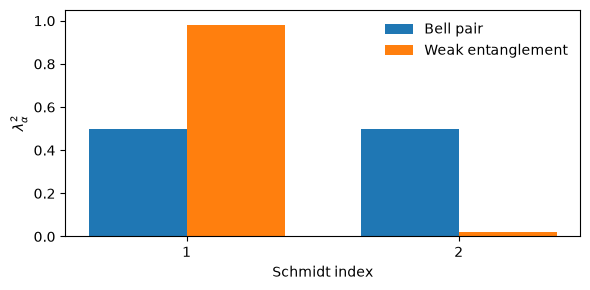

In [2]:
import numpy as np
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3))
positions = np.arange(2)
ax.bar(positions - 0.18, [0.5, 0.5], width=0.36, label="Bell pair")
ax.bar(positions + 0.18, [0.98, 0.02], width=0.36,
       label="Weak entanglement")
ax.set(xticks=positions, xticklabels=["1", "2"],
       xlabel="Schmidt index", ylabel=r"$\lambda_\alpha^2$", ylim=(0, 1.05))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Variational reasoning: an exact guarantee with limited reach 

Let $H|n\rangle=E_n|n\rangle$ with $E_0\leq E_1\leq\cdots$, and expand any normalized trial state as $|\psi_\theta\rangle=\sum_nc_n|n\rangle$. Orthogonality gives

$$
E(\theta)=\langle\psi_\theta|H|\psi_\theta\rangle
=\sum_n|c_n|^2E_n\geq E_0\sum_n|c_n|^2=E_0.
$$ 

This is a theorem, requiring a Hermitian Hamiltonian and a normalized state in its domain. In the continuum, the trial state's kinetic energy must exist and boundary conditions must be respected. For an unnormalized trial vector, use the Rayleigh quotient $\langle\psi|H|\psi\rangle/\langle\psi|\psi\rangle$. A finite Monte Carlo *estimate* may fall below $E_0$ through noise, and clipping a biased energy estimator does not preserve the theorem. The exact expectation is what is bounded.

Suppose the ground state is unique and the excitation gap is $\Delta=E_1-E_0>0$. Then

$$
E-E_0=\sum_{n>0}|c_n|^2(E_n-E_0)
\geq\Delta(1-|c_0|^2).
$$

Therefore the infidelity obeys $1-|\langle0|\psi\rangle|^2\leq(E-E_0)/\Delta$. Without a known gap this bound may be uninformative. Moreover an energy density error small compared with one does not ensure a small *total* energy error in a large system. Critical and nearly degenerate systems require particular care. Comparing energies alone is not sufficient to settle a phase diagram.

A useful second diagnostic is the variance $\operatorname{Var}_\psi(H)=\langle H^2\rangle-\langle H\rangle^2$. It vanishes exactly when $H|\psi\rangle=E|\psi\rangle$, because it is the squared norm of $(H-E)|\psi\rangle$. It identifies an eigenstate, not necessarily the ground state. An excited eigenstate has zero variance too.

## What the representation must let us do 

Before comparing architectures, specify access to a state. Can the algorithm evaluate $\psi(s)$ or only draw samples? Is its normalization known? Can it evaluate logarithmic derivatives with respect to every parameter? Can it efficiently obtain $\psi(s')/\psi(s)$ when a local operator changes a few spins? A local Hamiltonian connects each configuration to a relatively small number of others, so these ratios can be more useful than explicitly storing amplitudes.

There are also distinct learning tasks. In *variational simulation*, the Hamiltonian supplies an objective; there need not be any experimental training data. In *tomography*, repeated measurements constrain an unknown laboratory state. In *supervised emulation*, a network approximates outputs of a trusted solver. In *classification*, it may identify phases from snapshots without representing a wavefunction at all. A result in one task does not automatically transfer to another.

Neural quantum states were established as a practical variational strategy for representative interacting spin models by Carleo and Troyer [@q-carleo2017]. Their importance is the combination of a trainable amplitude representation and many-body variational algorithms. It is not a general theorem about efficient compression. Autoregressive models later made normalized sampling an architectural property [@q-hibatallah2020], while determinant networks encoded fermionic exchange directly [@q-pfau2020; @q-hermann2020]. These developments attack different bottlenecks; the following chapters derive how they fit together.

The 2026 perspective by Rigo and collaborators identifies unresolved issues in signs, bias, symmetry, optimization, and dynamics [@q-rigo2026]. It is a research perspective, not an independent certification of every benchmark. A productive research program starts with an observable or mechanism that existing tools cannot reliably resolve, chooses a representation for that difficulty, and then establishes independent tests. The scientific discovery is the robust physical conclusion, not merely a lower training loss.

## Exercises and selected solutions 

1. For $|\psi\rangle=\sqrt{3/4}|\uparrow\uparrow\rangle+\sqrt{1/4}|\downarrow\downarrow\rangle$, calculate $\rho_A$, its entropy, and $\langle\sigma_1^x\sigma_2^x\rangle$.
2. Repeat the two-spin diagonalization for $J=0$ and for $h=0$. Explain why the limits of eigenvectors at a degeneracy require a convention.
3. Show that $|+x\rangle^{\otimes N}$ has uniform $z$-measurement probabilities but zero entanglement across every cut. Explain why a broad probability distribution need not imply entanglement.
4. If a calculation has $E-E_0=0.01$ and a rigorously known gap $\Delta=0.2$, what fidelity is guaranteed? What changes if only the energy *per site* has error $0.01$ on 100 sites?
5. Construct the three-spin open-chain Ising Hamiltonian using tensor products and check its Hermiticity. Compare a dense eigensolver with explicit action on a vector; identify which stored object causes exponential memory use.

::: {.callout-tip title="Worked solutions"}
For exercise 1, tracing over $B$ removes the cross terms because $\langle\uparrow|\downarrow\rangle=0$. Thus $\rho_A=\operatorname{diag}(3/4,1/4)$ and $S_A=-(3/4)\log(3/4)-(1/4)\log(1/4)$. The flip operator exchanges the two occupied basis states, giving $2\sqrt{(3/4)(1/4)}=\sqrt3/2$. This off-diagonal correlation contains information absent from the reduced diagonal probabilities alone.

For exercise 4, the infidelity is at most $0.01/0.2=0.05$, so the fidelity is at least $0.95$. If the quoted error is per site, the total error is $1$, and the resulting lower bound $1-1/0.2=-4$ supplies no useful information beyond nonnegative fidelity. Energy accuracy must be interpreted in physical units and at the actual system size.
:::